# Runner nationality and round-number bunching: Boston and NYC

This notebook shows:

1. a sample of the **Boston** data with nationality (country of **residence**; Boston does not publish citizenship)
2. a sample of the **NYC** data with nationality (**citizenship**; residence is also available)
3. **bunching at 3:00, 4:00 and 5:00** by nationality, estimated as in Allen, Dechow, Pope and Wu (2017), with t-tests for significance

It reads files produced by the scripts in `src/` (run order in `README.md`): the matched study rows in
`scraped_data/` and the result tables in `output/`. Results use **fractional assignment**: when runners from
different countries share a match key (finishing second, age, gender), each study row is split across those
countries by their shares, held in a `weight` column.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import country_clusters as cc
import boston_nationality_clusters as bnc
import nyc_nationality_clusters as nnc

BOSTON_DIR, NYC_DIR = ROOT / 'scraped_data' / 'boston', ROOT / 'scraped_data' / 'nyc'
BOSTON_OUT, NYC_OUT = ROOT / 'output' / 'boston', ROOT / 'output' / 'nyc'
POINTS = ['3:00', '4:00', '5:00']

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)


def finish_time(minutes):
    '''Format finishing time in minutes as H:MM:SS.'''
    seconds = (minutes * 60).round().astype(int)
    return (seconds // 3600).astype(str) + ':' + \
        (seconds % 3600 // 60).map('{:02d}'.format) + ':' + (seconds % 60).map('{:02d}'.format)

## 1. Boston: study rows with country of residence

In [2]:
boston = pd.read_csv(BOSTON_DIR / 'boston_study_with_nationality.csv',
                     usecols=['study_row', 'year', 'age', 'gender', 'chiptime', 'nationality',
                              'nationality_region', 'match_status'])
boston = boston.rename(columns={'nationality': 'residence', 'nationality_region': 'residence_region'})
boston['finish_time'] = finish_time(boston['chiptime'])

print(f'{len(boston):,} Boston study rows (2004-07, 2013); '
      f'{boston["residence"].notna().mean():.1%} have a single country (exact assignment)')
boston[boston['residence'].notna()].sample(10, random_state=1)[
    ['year', 'age', 'gender', 'finish_time', 'residence', 'residence_region', 'match_status']]

91,862 Boston study rows (2004-07, 2013); 98.6% have a single country (exact assignment)


,year,age,gender,finish_time,residence,residence_region,match_status
43386,2006,55.0,M,3:41:50,USA,U.S.,unique
1423,2004,40.0,M,3:22:35,USA,U.S.,unique
43151,2006,25.0,F,3:40:52,USA,U.S.,unique
66037,2007,29.0,F,3:56:11,USA,U.S.,unique
27398,2005,45.0,M,4:02:27,USA,U.S.,unique
86027,2013,66.0,M,3:41:39,CAN,Canada,unique
45112,2006,58.0,M,3:49:14,USA,U.S.,unique
28258,2005,52.0,M,4:08:02,USA,U.S.,unique
59156,2007,46.0,M,3:28:46,USA,U.S.,unique
75518,2013,56.0,M,2:54:56,USA,U.S.,unique


In [3]:
print('Most common countries of residence (exact assignment):')
boston['residence'].value_counts().head(10).to_frame('runners')

Most common countries of residence (exact assignment):


,runners
residence,
USA,78155
CAN,7342
GER,636
KOR,633
GBR,501
JPN,476
MEX,418
ITA,276
IRL,208


## 2. NYC: study rows with citizenship (and residence)

Gender is blank for 2010 because the study data has none that year; those rows were matched on time and age.

In [4]:
nyc = pd.read_csv(NYC_DIR / 'nyc_study_with_nationality.csv',
                  usecols=['study_row', 'year', 'age', 'gender', 'chiptime', 'nationality',
                           'country_residence', 'nationality_region', 'status'],
                  dtype={'gender': str})   # gender is blank for 2010 (not in the study data)
nyc = nyc.rename(columns={'nationality': 'citizenship', 'nationality_region': 'citizenship_region',
                          'status': 'match_status'})
nyc['finish_time'] = finish_time(nyc['chiptime'])

has = nyc['citizenship'].notna()
print(f'{len(nyc):,} NYC study rows (2006-11, 2013); {has.mean():.1%} have a single citizenship (exact assignment)')
print(f'Citizenship differs from residence for {(nyc.loc[has, "citizenship"] != nyc.loc[has, "country_residence"]).mean():.1%} of them')
nyc[has].sample(10, random_state=1)[
    ['year', 'age', 'gender', 'finish_time', 'citizenship', 'country_residence', 'citizenship_region', 'match_status']]

300,759 NYC study rows (2006-11, 2013); 93.4% have a single citizenship (exact assignment)
Citizenship differs from residence for 9.6% of them


,year,age,gender,finish_time,citizenship,country_residence,citizenship_region,match_status
225150,2011,51.0,M,4:17:49,FRA,FRA,Europe,unique
80619,2008,30.0,F,3:26:48,USA,USA,U.S.,unique
201664,2010,60.0,NaN,6:15:54,USA,USA,U.S.,unique
139773,2009,30.0,F,4:27:45,USA,USA,U.S.,unique
109420,2008,36.0,M,5:19:04,USA,USA,U.S.,unique
46039,2007,21.0,M,3:48:18,BEL,BEL,Europe,unique
245780,2011,55.0,M,5:34:57,USA,USA,U.S.,unique
165374,2010,44.0,NaN,3:38:16,USA,USA,U.S.,unique
193370,2010,33.0,NaN,5:01:21,USA,USA,U.S.,unique
285296,2013,44.0,M,4:47:29,MEX,MEX,Other,unique


In [5]:
print('Most common citizenships (exact assignment):')
nyc['citizenship'].value_counts().head(10).to_frame('runners')

Most common citizenships (exact assignment):


,runners
citizenship,
USA,135952
ITA,19813
FRA,19503
ENG,16399
DEU,15129
NLD,10364
CAN,7592
MEX,4731
ESP,4574


### Fractional assignment

Rows the exact match could not resolve (a match key shared by runners of different countries) are split across
those countries. Each study row's weights sum to 1. Some NYC examples:

In [6]:
frac_nyc = pd.read_csv(NYC_DIR / 'nyc_fractional_nationality.csv')
split = frac_nyc[frac_nyc['weight'] < 1]
example_rows = split['study_row'].drop_duplicates().sample(3, random_state=2)
print(f'{frac_nyc["study_row"].nunique():,} NYC study rows covered '
      f'({frac_nyc["study_row"].nunique() / len(nyc):.1%}); {split["study_row"].nunique():,} of them split across countries')
split[split['study_row'].isin(example_rows)].sort_values(['study_row', 'weight'])

299,144 NYC study rows covered (99.5%); 17,357 of them split across countries


,study_row,nationality,year,weight,match_status
154089,6890846,ENG,2009,0.5,group_mixed_country
154090,6890846,FRA,2009,0.5,group_mixed_country
180539,6915924,CAN,2010,0.5,group_mixed_country
180540,6915924,NIR,2010,0.5,group_mixed_country
270374,7000827,FRA,2013,0.5,group_mixed_country
270375,7000827,SWE,2013,0.5,group_mixed_country


## 3. Bunching at 3:00, 4:00 and 5:00

Method, as in the paper (Chetty et al. 2011 excess mass):

* finishing times in 15-second bins; window of 8 minutes either side of the round number
* a cubic counterfactual is fitted to the bins outside the **bunching region** (the 4 minutes before the round
  number) and shifted so it holds the same number of finishers as the actual counts
* **excess** = % more finishers in the bunching region than the counterfactual predicts
* **t** = excess / bootstrap standard error (500 resamples of the finishers in the window);
  **p** is two-sided from the normal distribution; `*` p < .05, `**` p < .01, `***` p < .001

A usable estimate needs roughly 1,000 finishers in the window (`n` columns); smaller groups are shown but noisy.

In [7]:
def stars(p):
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''


def results_table(name, out_dir, min_finishers=0):
    '''Excess, t, p and significance at 3:00, 4:00 and 5:00 from a saved result table.'''
    wide = pd.read_csv(out_dir / f'{name}.csv', index_col=0)
    long = pd.read_csv(out_dir / f'{name}_long.csv')
    n_window = long.pivot(index=long.columns[0], columns='ref_point', values='n_window')

    table = pd.DataFrame({'finishers': wide['n_finishers'].round().astype(int)})
    for point in POINTS:
        t = wide[f't_stat_{point}']
        p = pd.Series(2 * stats.norm.sf(t.abs()), index=t.index)
        table[f'{point} excess %'] = wide[f'excess_pct_{point}'].round(2)
        table[f'{point} t'] = t.round(2)
        table[f'{point} p'] = p.round(3)
        table[f'{point} sig'] = p.map(stars)
        table[f'{point} n'] = n_window[point].reindex(table.index).astype('Int64')
    return table[table['finishers'] >= min_finishers]

### Boston, by region of residence

In [8]:
results_table('boston_excess_mass_by_nationality_region_fractional', BOSTON_OUT)

,finishers,3:00 excess %,3:00 t,3:00 p,3:00 sig,3:00 n,4:00 excess %,4:00 t,4:00 p,4:00 sig,4:00 n,5:00 excess %,5:00 t,5:00 p,5:00 sig,5:00 n
nationality_region,,,,,,,,,,,,,,,,
U.S.,78759,21.81,5.57,0.000,***,5322,7.22,3.37,0.001,***,12990,3.26,0.75,0.453,,2941
Canada,7749,11.57,0.96,0.337,,496,-3.17,-0.54,0.589,,1499,0.97,0.04,0.968,,134
Europe,2739,39.56,2.37,0.018,*,310,25.88,1.71,0.087,,374,-44.44,-2.34,0.019,*,67
Other,2595,25.52,1.25,0.211,,209,-5.40,-0.55,0.582,,402,-30.52,-1.43,0.153,,76


### Boston, by country of residence (only the U.S. and Canada have enough runners; others are noisy)

In [9]:
results_table('boston_excess_mass_by_nationality_fractional', BOSTON_OUT)

,finishers,3:00 excess %,3:00 t,3:00 p,3:00 sig,3:00 n,4:00 excess %,4:00 t,4:00 p,4:00 sig,4:00 n,5:00 excess %,5:00 t,5:00 p,5:00 sig,5:00 n
nationality,,,,,,,,,,,,,,,,
USA,78759,21.81,5.57,0.000,***,5322,7.22,3.37,0.001,***,12990,3.26,0.75,0.453,,2941
CAN,7749,11.57,0.96,0.337,,496,-3.17,-0.54,0.589,,1499,0.97,0.04,0.968,,134
GER,659,-3.91,-0.10,0.920,,51,36.21,1.15,0.250,,113,-47.21,-1.73,0.084,,30
KOR,654,-6.65,-0.13,0.897,,18,-8.10,-0.50,0.617,,135,-49.80,-2.24,0.025,*,29
GBR,533,66.45,1.44,0.150,,57,3.77,0.13,0.897,,66,-48.27,-1.55,0.121,,12
JPN,487,47.98,0.17,0.865,,34,9.23,0.30,0.764,,70,72.23,0.16,0.873,,27
MEX,453,116.94,0.26,0.795,,41,-18.79,-0.72,0.472,,73,-42.32,-0.89,0.373,,9


### NYC, by region of citizenship

In [10]:
results_table('nyc_excess_mass_by_nationality_region_fractional', NYC_OUT)

,finishers,3:00 excess %,3:00 t,3:00 p,3:00 sig,3:00 n,4:00 excess %,4:00 t,4:00 p,4:00 sig,4:00 n,5:00 excess %,5:00 t,5:00 p,5:00 sig,5:00 n
nationality_region,,,,,,,,,,,,,,,,
U.S.,141723,24.38,5.00,0.000,***,3206,14.72,7.44,0.000,***,18394,2.25,1.06,0.289,,13054
Europe,118529,31.91,6.01,0.000,***,3246,10.92,6.31,0.000,***,18126,8.62,3.32,0.001,***,9644
Other,30739,31.86,2.73,0.006,**,769,14.42,3.93,0.000,***,4295,0.27,0.06,0.952,,2616
Canada,8153,21.49,1.33,0.184,,270,6.10,0.85,0.395,,1108,8.54,0.90,0.368,,689


### NYC, by region of residence (for comparison)

In [11]:
results_table('nyc_excess_mass_by_residence_region_fractional', NYC_OUT)

,finishers,3:00 excess %,3:00 t,3:00 p,3:00 sig,3:00 n,4:00 excess %,4:00 t,4:00 p,4:00 sig,4:00 n,5:00 excess %,5:00 t,5:00 p,5:00 sig,5:00 n
residence_region,,,,,,,,,,,,,,,,
U.S.,159143,27.64,5.42,0.000,***,3932,12.41,7.05,0.000,***,20955,3.04,1.46,0.144,,14234
Europe,110042,30.61,5.35,0.000,***,2897,13.06,6.97,0.000,***,16763,8.00,2.95,0.003,**,9133
Other,23259,25.52,1.85,0.064,,424,15.68,3.58,0.000,***,3319,1.85,0.37,0.711,,2047
Canada,7221,17.67,1.13,0.258,,250,6.51,0.81,0.418,,950,-0.57,-0.06,0.952,,631


### NYC, by country of citizenship (countries with 2,000+ finishers)

Countries with fewer than about 800 runners in the 4:00 window (`4:00 n`) are too small to interpret.

In [12]:
results_table('nyc_excess_mass_by_nationality_fractional', NYC_OUT)

,finishers,3:00 excess %,3:00 t,3:00 p,3:00 sig,3:00 n,4:00 excess %,4:00 t,4:00 p,4:00 sig,4:00 n,5:00 excess %,5:00 t,5:00 p,5:00 sig,5:00 n
nationality,,,,,,,,,,,,,,,,
USA,141723,24.38,5.00,0.000,***,3206,14.72,7.44,0.000,***,18394,2.25,1.06,0.289,,13054
ITA,21378,29.44,2.27,0.023,*,678,7.89,1.81,0.070,,2991,3.87,0.60,0.549,,1572
FRA,21321,24.57,2.10,0.036,*,618,12.69,3.11,0.002,**,3542,3.90,0.63,0.529,,1616
ENG,17679,29.99,2.24,0.025,*,356,10.74,2.32,0.020,*,2422,18.21,2.79,0.005,**,1584
DEU,16396,34.92,2.14,0.032,*,324,18.12,3.73,0.000,***,2428,-0.52,-0.10,0.920,,1656
NLD,11218,45.48,1.49,0.136,,120,10.55,2.03,0.042,*,1914,18.85,2.35,0.019,*,1038
CAN,8153,21.49,1.37,0.171,,270,6.10,0.86,0.390,,1108,8.54,0.88,0.379,,689
MEX,5164,6.87,0.28,0.779,,135,23.49,2.23,0.026,*,793,-16.42,-1.72,0.085,,452
ESP,5074,44.59,2.27,0.023,*,295,-17.17,-2.56,0.010,*,852,28.57,1.26,0.208,,266


### Check: does the matching change the overall estimate?

`All study rows` needs no nationality, so it is the benchmark. Exact assignment (dropping mixed keys) loses
runners who pile up at round numbers and understates NYC bunching; fractional assignment matches the benchmark.

In [13]:
for race, out_dir in [('Boston', BOSTON_OUT), ('NYC', NYC_OUT)]:
    check = pd.read_csv(out_dir / f'{race.lower()}_nationality_sample_check.csv', index_col=0)
    print(race)
    display(check[['n_finishers'] + [f'excess_pct_{p}' for p in POINTS] + [f't_stat_{p}' for p in POINTS]].round(2))

Boston


,n_finishers,excess_pct_3:00,excess_pct_4:00,excess_pct_5:00,t_stat_3:00,t_stat_4:00,t_stat_5:00
sample,,,,,,,
All study rows,91862.0,22.12,6.17,0.91,6.26,3.02,0.21
Fractional assignment,91842.0,22.09,6.19,0.91,6.28,3.20,0.21
Nationality assigned,90584.0,22.20,5.77,1.45,6.46,2.99,0.35
Dropped,1278.0,17.04,38.96,-100.00,0.58,1.56,NaN


NYC


,n_finishers,excess_pct_3:00,excess_pct_4:00,excess_pct_5:00,t_stat_3:00,t_stat_4:00,t_stat_5:00
sample,,,,,,,
All study rows,300759.0,28.79,12.83,4.61,8.97,10.56,3.19
Fractional assignment,299144.0,28.12,12.76,4.54,8.33,10.53,3.04
Exact assignment,280890.0,25.15,11.21,4.37,7.63,8.41,2.83
Dropped by exact assignment,19869.0,200.86,24.59,9.12,3.65,6.49,1.42


## 4. Picture: actual finishers vs counterfactual (NYC, U.S. vs Europe citizens)

Bars are finishers per 15-second bin (weighted); the line is the fitted counterfactual; the shaded area is the
bunching region.

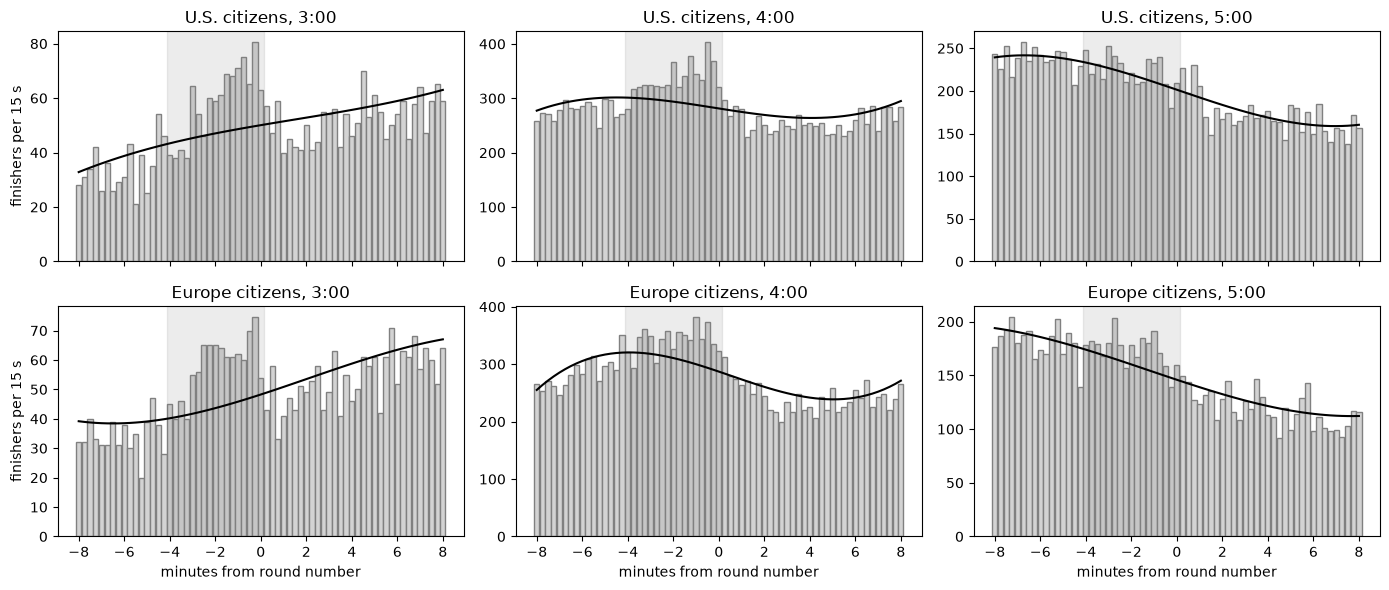

In [14]:
frac = frac_nyc.merge(nyc[['study_row', 'chiptime']], on='study_row')
frac['bin_time'] = cc.to_time_bins(frac['chiptime'])
frac['region'] = frac['nationality'].replace(nnc.CODE_FIXES).map(nnc.nationality_region)


def counterfactual(counts, bins, point, degree=cc.POLY_DEGREE, region=cc.BUNCH_REGION):
    '''Fitted counterfactual, as in country_clusters.estimate_excess_mass.'''
    x = (bins - point) / (bins.max() - point)
    design = np.vander(x, degree + 1)
    inside = (bins >= point - region) & (bins <= point)
    coefs = np.linalg.lstsq(design[~inside], counts[~inside], rcond=None)[0]
    fitted = design @ coefs
    return fitted + (counts.sum() - fitted.sum()) / len(bins)


groups = ['U.S.', 'Europe']
fig, axes = plt.subplots(len(groups), 3, figsize=(14, 6), sharex='col')
for i, group in enumerate(groups):
    sub = frac[frac['region'] == group]
    for j, point in enumerate([180, 240, 300]):
        bins = cc.window_bins(point)
        counts = (sub[sub['bin_time'].isin(bins)].groupby('bin_time')['weight'].sum()
                  .reindex(bins, fill_value=0).to_numpy())
        fitted = counterfactual(counts, bins, point)
        ax = axes[i, j]
        ax.bar(bins - point, counts, width=0.23, color='lightgray', edgecolor='gray')
        ax.plot(bins - point, fitted, color='black')
        ax.axvspan(-cc.BUNCH_REGION - 0.125, 0.125, color='gray', alpha=0.15)
        ax.set_title(f'{group} citizens, {cc.format_minutes(point)}')
        if j == 0:
            ax.set_ylabel('finishers per 15 s')
        if i == len(groups) - 1:
            ax.set_xlabel('minutes from round number')
plt.tight_layout()
plt.show()

## 5. Recompute live (Boston regions)

The tables above are read from `output/`. This reruns the estimate for Boston regions from the matched data to
show it reproduces them (point estimates match exactly; t-statistics can differ slightly because the bootstrap
draws depend on the order groups are estimated in).

In [15]:
frac_boston = pd.read_csv(BOSTON_DIR / 'boston_fractional_residence.csv')
study_cols = pd.read_csv(BOSTON_DIR / 'boston_study_with_nationality.csv',
                         usecols=['study_row', 'chiptime', 'bin_time', 'marathon2'])
weighted = frac_boston.merge(study_cols, on='study_row')
weighted['region'] = weighted['country_residence'].map(bnc.nationality_region)

live = cc.make_excess_mass_table(weighted, 'region', ref_points=[180, 240, 300], min_finishers=1000)
live

,n_marathon_years,mean_time,n_finishers,excess_pct_3:00,t_stat_3:00,excess_pct_4:00,t_stat_4:00,excess_pct_5:00,t_stat_5:00
region,,,,,,,,,
U.S.,5,233.94,78759.0,21.81,5.57,7.22,3.37,3.26,0.75
Canada,5,227.13,7749.0,11.57,0.96,-3.17,-0.54,0.97,0.04
Europe,5,222.08,2739.0,39.56,2.37,25.88,1.71,-44.44,-2.34
Other,5,227.83,2595.0,25.52,1.25,-5.40,-0.55,-30.52,-1.43
